# GPU warp scheduling — validated performance analysis

Below are the key metrics:

- `gpu_tot_sim_cycle` → `cycles`
- `gpu_tot_sim_insn` → `instructions`
- `gpu_tot_ipc` → `ipc`

## 1. Load and check the validated CSV

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SCHEDULERS = ["lrr", "gto", "rrr", "oldest", "wl4", "wl8", "wl16"]
CORE = ["lrr", "gto", "rrr", "oldest"]
WARP_LIMITS = ["wl4", "wl8", "wl16"]
WORKLOADS = [
    "bfs", "nw", "nn", "lud", "srad_v2", "hotspot", "backprop",
    "heartwall", "pathfinder", "streamcluster",
]

# Works whether the notebook is launched from the repo root or notebooks/.
ROOT = Path.cwd().resolve()
if not (ROOT / "results" / "feasibility" / "results_validated.csv").is_file():
    ROOT = ROOT.parent

CSV_PATH = ROOT / "results" / "feasibility" / "results_validated.csv"
PLOT_DIR = ROOT / "plots" / "validated"
SAVE_PLOTS = False  # Set True if you want PNGs under plots/validated/

if not CSV_PATH.is_file():
    raise FileNotFoundError(
        f"Cannot find {CSV_PATH}. Run python scripts/validate_feasibility.py first."
    )

if SAVE_PLOTS:
    PLOT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(CSV_PATH)
print(f"Loaded {len(df)} rows from {CSV_PATH}")


Loaded 70 rows from /home/ewong/gpu-warp-scheduling/results/feasibility/results_validated.csv


In [2]:
required = {
    "workload", "scheduler", "status", "cycles", "instructions", "ipc",
    "exit_code", "stat_blocks", "validation_notes",
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing expected columns: {sorted(missing)}")

# Do not silently plot results that failed validation.
problem_rows = df.loc[df["status"] != "PASS"]
if not problem_rows.empty:
    display(problem_rows[["workload", "scheduler", "status", "validation_notes"]])
    raise ValueError("Some runs did not pass validation. Resolve them before plotting.")

if df.duplicated(["workload", "scheduler"]).any():
    raise ValueError("Duplicate workload/scheduler rows found.")

expected = pd.MultiIndex.from_product(
    [WORKLOADS, SCHEDULERS], names=["workload", "scheduler"]
)
actual = pd.MultiIndex.from_frame(df[["workload", "scheduler"]])
if set(expected) != set(actual) or len(df) != len(expected):
    raise ValueError("Expected exactly 10 workloads × 7 schedulers = 70 unique runs.")

for col in ["cycles", "instructions", "ipc"]:
    df[col] = pd.to_numeric(df[col], errors="raise")
if (df[["cycles", "instructions", "ipc"]] <= 0).any().any():
    raise ValueError("Found non-positive performance counters.")
if not (pd.to_numeric(df["exit_code"], errors="raise") == 0).all():
    raise ValueError("At least one simulation has a nonzero exit code.")

# The simulator prints IPC to four decimal places, hence a small tolerance.
recomputed_ipc = df["instructions"] / df["cycles"]
if not np.allclose(recomputed_ipc, df["ipc"], rtol=0, atol=0.001):
    raise ValueError("Reported IPC is inconsistent with total instructions / total cycles.")

if (df.groupby("workload")["instructions"].nunique() != 1).any():
    raise ValueError("Instruction counts differ across schedulers for a workload.")

print("PASS: 70 unique runs, exit codes, cumulative IPC, and instruction counts checked.")
print("Statistics blocks per run:")
display(df.groupby("workload")["stat_blocks"].agg(["min", "max"]))
display(df[["workload", "scheduler", "cycles", "instructions", "ipc"]].head(10))


PASS: 70 unique runs, exit codes, cumulative IPC, and instruction counts checked.
Statistics blocks per run:


,min,max
workload,,
backprop,2,2
bfs,16,16
heartwall,1,1
hotspot,7,7
lud,10,10
nn,4,4
nw,15,15
pathfinder,4,4
srad_v2,4,4


,workload,scheduler,cycles,instructions,ipc
0,bfs,lrr,115610,1207402,10.4438
1,bfs,gto,115226,1207402,10.4786
2,bfs,rrr,128753,1207402,9.3777
3,bfs,oldest,115286,1207402,10.4731
4,bfs,wl4,115226,1207402,10.4786
5,bfs,wl8,115226,1207402,10.4786
6,bfs,wl16,115226,1207402,10.4786
7,nw,lrr,133487,572068,4.2856
8,nw,gto,133487,572068,4.2856
9,nw,rrr,133448,572068,4.2868


## 2. Calculate normalized speedup

For each workload, the LRR baseline is 1.0:

$$\mathrm{Speedup}_{s} = \frac{\mathrm{Cycles}_{LRR}}{\mathrm{Cycles}_{s}}$$

Above 1.0 means faster than LRR; below 1.0 means slower. Simulated cycles for the entire workload is used for comparison.


In [3]:
cycles = (
    df.pivot(index="workload", columns="scheduler", values="cycles")
      .reindex(index=WORKLOADS, columns=SCHEDULERS)
)
ipc = (
    df.pivot(index="workload", columns="scheduler", values="ipc")
      .reindex(index=WORKLOADS, columns=SCHEDULERS)
)
speedup = cycles["lrr"].to_numpy()[:, None] / cycles.to_numpy()
speedup = pd.DataFrame(speedup, index=WORKLOADS, columns=SCHEDULERS)

print("Normalized speedup relative to LRR (greater than 1 = faster):")
display(speedup.round(4))


Normalized speedup relative to LRR (greater than 1 = faster):


,lrr,gto,rrr,oldest,wl4,wl8,wl16
bfs,1.0,1.0033,0.8979,1.0028,1.0033,1.0033,1.0033
nw,1.0,1.0000,1.0003,1.0000,1.0000,1.0000,1.0000
nn,1.0,0.9933,0.9279,1.0199,0.9933,0.9933,0.9933
lud,1.0,0.9987,0.9997,0.9994,0.9987,0.9987,0.9987
srad_v2,1.0,0.9956,0.9717,0.9955,0.9956,0.9956,0.9956
hotspot,1.0,1.0091,0.9676,1.0035,1.0091,1.0091,1.0091
backprop,1.0,1.0504,0.9332,1.0473,1.0001,1.0504,1.0504
heartwall,1.0,1.0063,0.8953,1.0103,1.0063,1.0063,1.0063
pathfinder,1.0,1.0024,0.9881,1.0048,1.0024,1.0024,1.0024
streamcluster,1.0,1.0028,0.9529,1.0020,1.0028,1.0028,1.0028


## 3. Overall speedup heatmap — all seven configurations

The heatmap makes it easier to identify workloads where scheduler choice actually matters. 

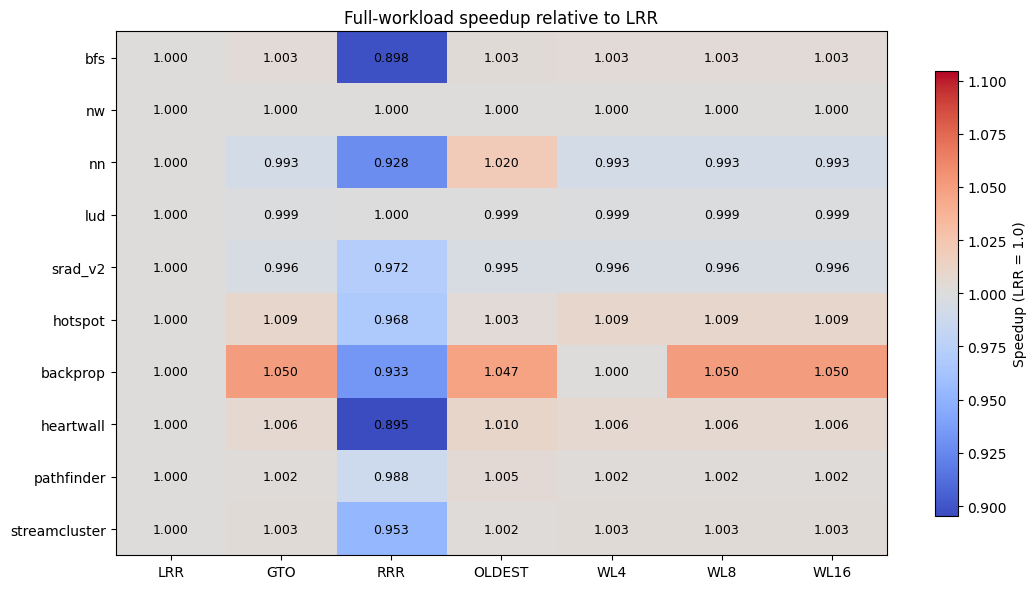

In [4]:
from matplotlib.colors import TwoSlopeNorm

values = speedup.to_numpy()
spread = max(abs(values.min() - 1.0), abs(values.max() - 1.0), 0.005)

fig, ax = plt.subplots(figsize=(11, 6))
img = ax.imshow(
    values,
    aspect="auto",
    cmap="coolwarm",
    norm=TwoSlopeNorm(vmin=1.0 - spread, vcenter=1.0, vmax=1.0 + spread),
)
ax.set_xticks(range(len(SCHEDULERS)), [s.upper() for s in SCHEDULERS])
ax.set_yticks(range(len(WORKLOADS)), WORKLOADS)
ax.set_title("Full-workload speedup relative to LRR")
for i in range(len(WORKLOADS)):
    for j in range(len(SCHEDULERS)):
        ax.text(j, i, f"{values[i,j]:.3f}", ha="center", va="center", fontsize=9)
fig.colorbar(img, ax=ax, label="Speedup (LRR = 1.0)", shrink=0.85)
fig.tight_layout()
if SAVE_PLOTS:
    fig.savefig(PLOT_DIR / "speedup_heatmap.png", dpi=200)
plt.show()


## 4. Core scheduler comparison

Only LRR, GTO, RRR, and Oldest are compared. Warp-limiting is not tested here.

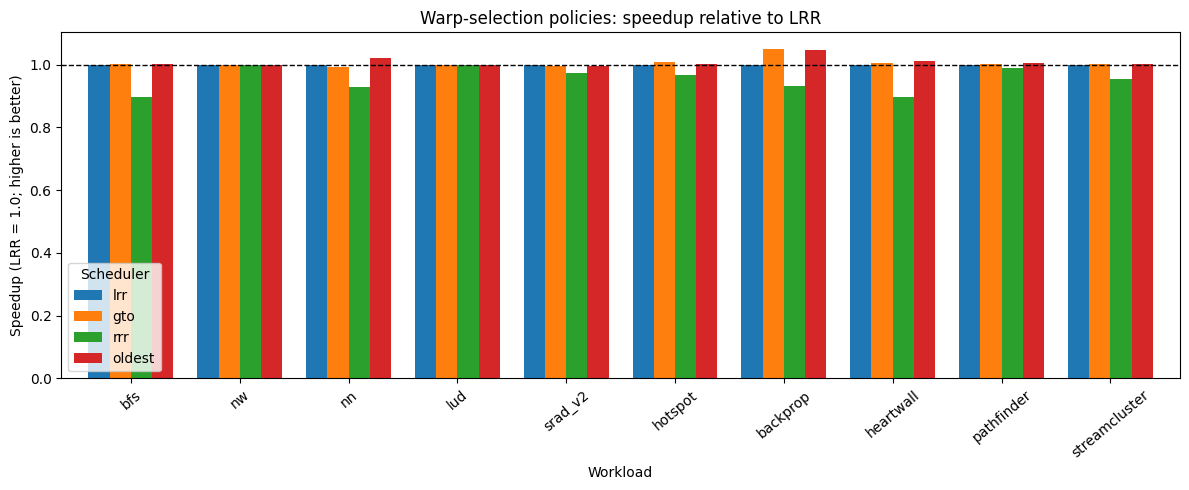

In [5]:
ax = speedup[CORE].plot.bar(figsize=(12, 5), width=0.78)
ax.axhline(1.0, linestyle="--", linewidth=1, color="black")
ax.set_title("Warp-selection policies: speedup relative to LRR")
ax.set_xlabel("Workload")
ax.set_ylabel("Speedup (LRR = 1.0; higher is better)")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Scheduler")
plt.tight_layout()
if SAVE_PLOTS:
    plt.savefig(PLOT_DIR / "core_schedulers_speedup.png", dpi=200)
plt.show()


## 5. Static warp limiting versus unrestricted GTO

The warp-limit tests are performed on GTO and changes only the number of warps considered per scheduler. These results are compared against GTO to isolate the effect of the limit.

Percentage change is computed as $100 \times (\mathrm{Cycles}_{GTO}/\mathrm{Cycles}_{WL} - 1)$.
A positive value means the limited configuration is faster than unrestricted GTO.

,WL4 (%),WL8 (%),WL16 (%)
bfs,0.000,0.0,0.0
nw,0.000,0.0,0.0
nn,0.000,0.0,0.0
lud,0.000,0.0,0.0
srad_v2,0.000,0.0,0.0
hotspot,0.000,0.0,0.0
backprop,-4.786,0.0,0.0
heartwall,0.000,0.0,0.0
pathfinder,0.000,0.0,0.0
streamcluster,0.000,0.0,0.0


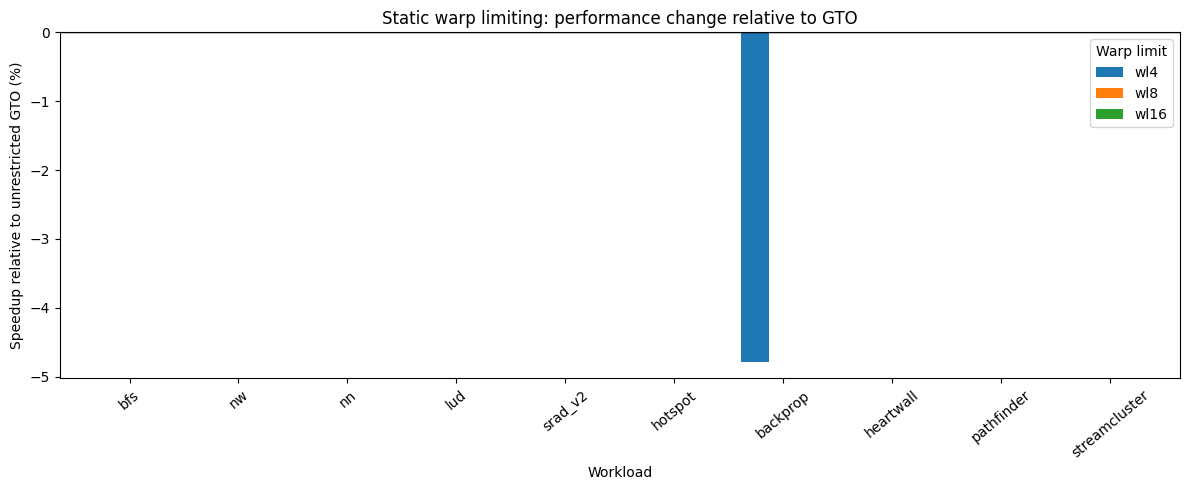

In [6]:
wl_change = (cycles["gto"].to_numpy()[:, None] / cycles[WARP_LIMITS].to_numpy() - 1) * 100
wl_change = pd.DataFrame(wl_change, index=WORKLOADS, columns=WARP_LIMITS)

display(wl_change.round(3).rename(columns=lambda x: x.upper() + " (%)"))
ax = wl_change.plot.bar(figsize=(12, 5), width=0.78)
ax.axhline(0.0, linewidth=1, color="black")
ax.set_title("Static warp limiting: performance change relative to GTO")
ax.set_xlabel("Workload")
ax.set_ylabel("Speedup relative to unrestricted GTO (%)")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Warp limit")
plt.tight_layout()
if SAVE_PLOTS:
    plt.savefig(PLOT_DIR / "warp_limiting_vs_gto.png", dpi=200)
plt.show()


## 6. Workload scheduling sensitivity

,fastest,slowest,best_cycles,worst_cycles,performance_spread_pct
heartwall,oldest,rrr,8180,9230,11.376
backprop,gto,rrr,14007,15767,11.163
bfs,gto,rrr,115226,128753,10.506
nn,oldest,rrr,29687,32630,9.019
streamcluster,gto,rrr,1149036,1209233,4.978
hotspot,gto,rrr,53797,56107,4.117
srad_v2,lrr,rrr,29102,29949,2.828
pathfinder,oldest,rrr,29039,29528,1.656
lud,lrr,gto,135600,135773,0.127
nw,rrr,lrr,133448,133487,0.029


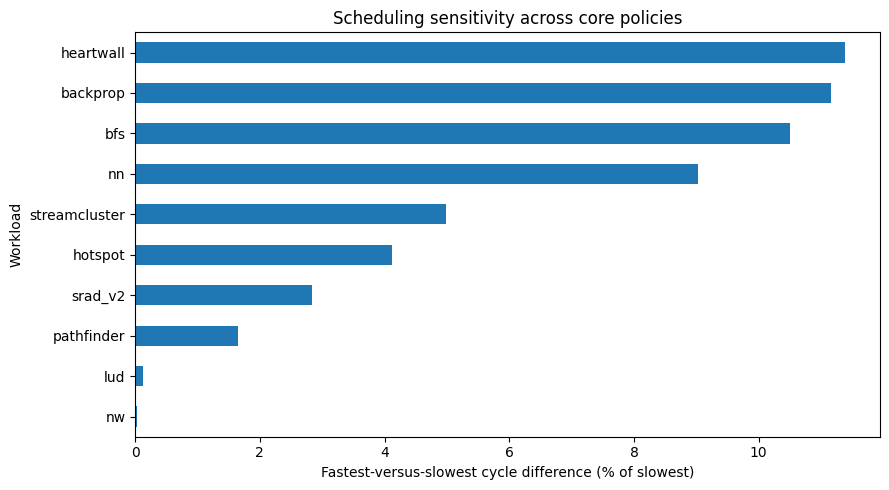

In [7]:
core_cycles = cycles[CORE]
sensitivity = pd.DataFrame(index=WORKLOADS)
sensitivity["fastest"] = core_cycles.idxmin(axis=1)
sensitivity["slowest"] = core_cycles.idxmax(axis=1)
sensitivity["best_cycles"] = core_cycles.min(axis=1)
sensitivity["worst_cycles"] = core_cycles.max(axis=1)
sensitivity["performance_spread_pct"] = (
    (sensitivity["worst_cycles"] - sensitivity["best_cycles"])
    / sensitivity["worst_cycles"] * 100
)
sensitivity = sensitivity.sort_values("performance_spread_pct", ascending=False)

display(sensitivity.round(3))
ax = sensitivity["performance_spread_pct"].sort_values().plot.barh(figsize=(9, 5))
ax.set_title("Scheduling sensitivity across core policies")
ax.set_xlabel("Fastest-versus-slowest cycle difference (% of slowest)")
ax.set_ylabel("Workload")
plt.tight_layout()
if SAVE_PLOTS:
    plt.savefig(PLOT_DIR / "scheduler_sensitivity.png", dpi=200)
plt.show()


## 7. Zoomed IPC bar charts for every workload

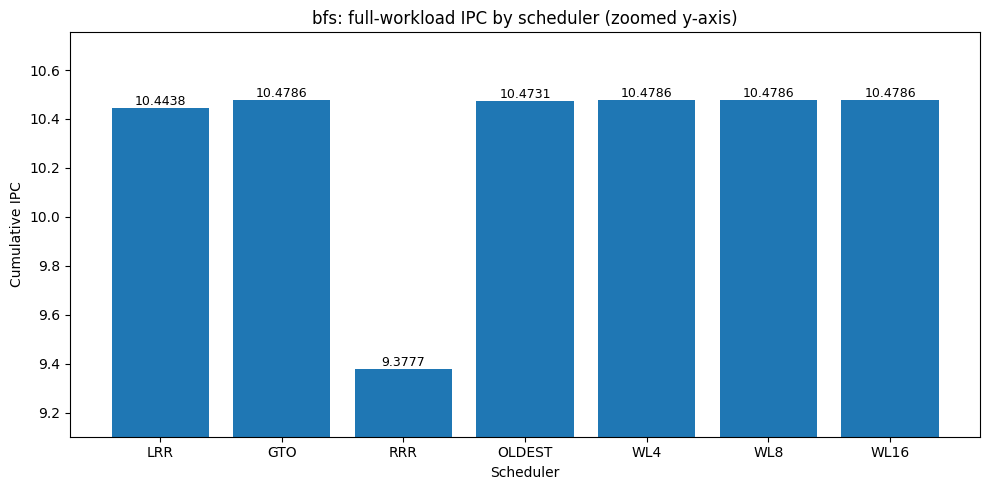

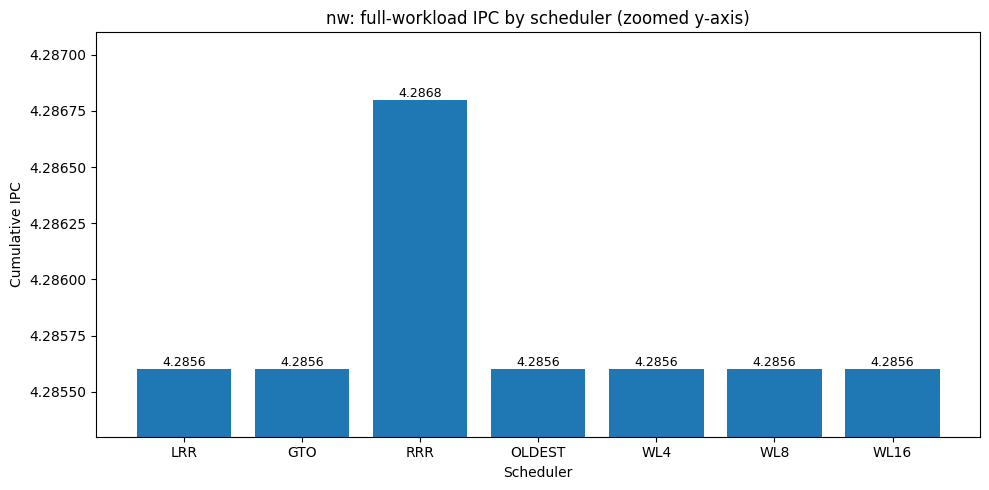

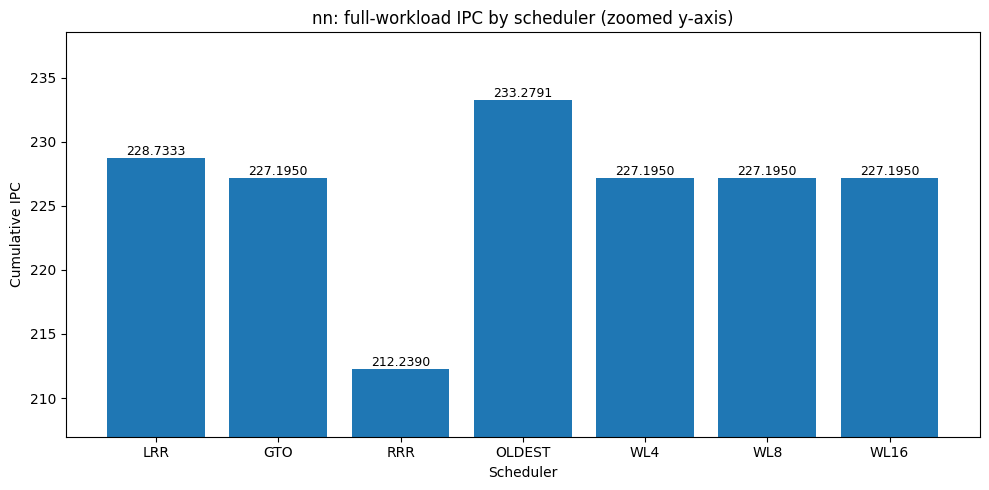

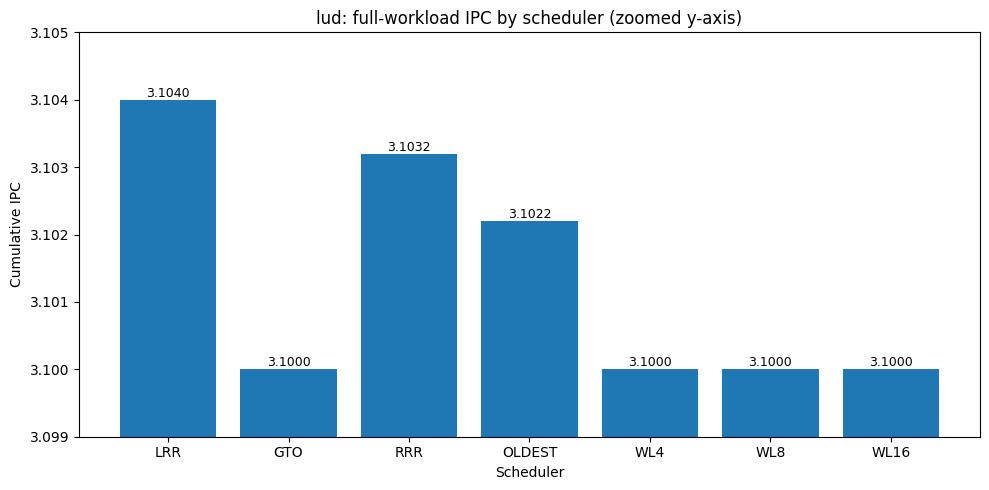

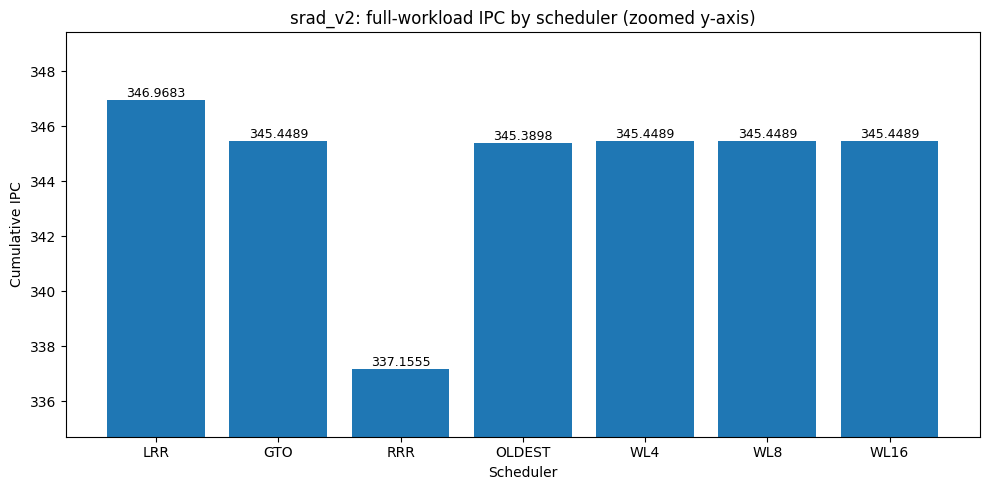

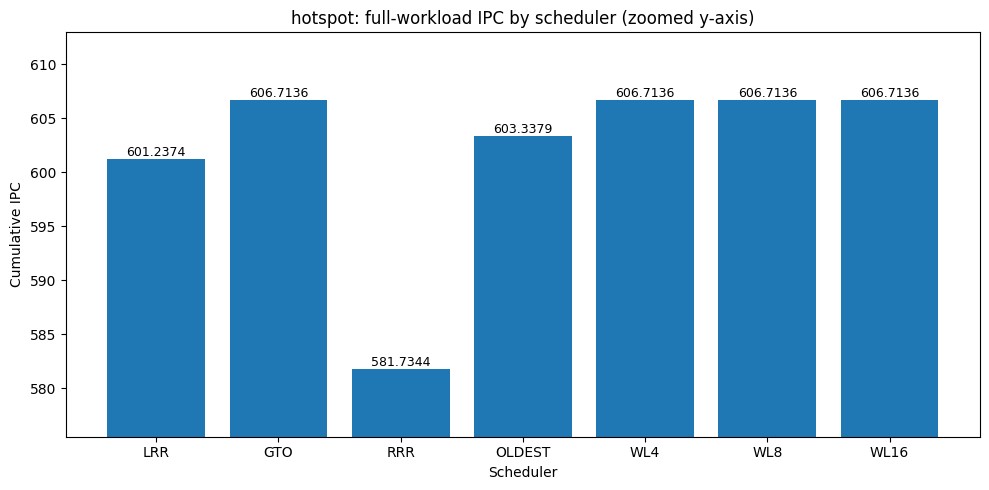

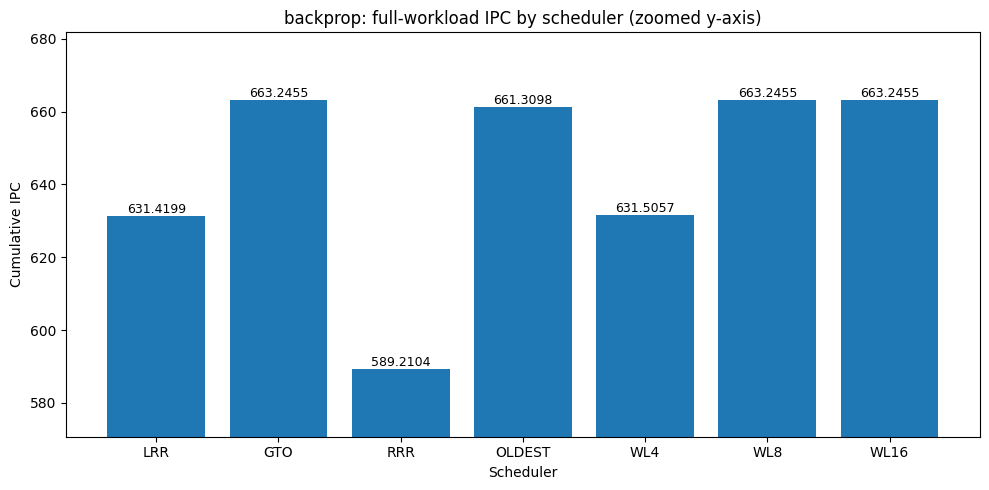

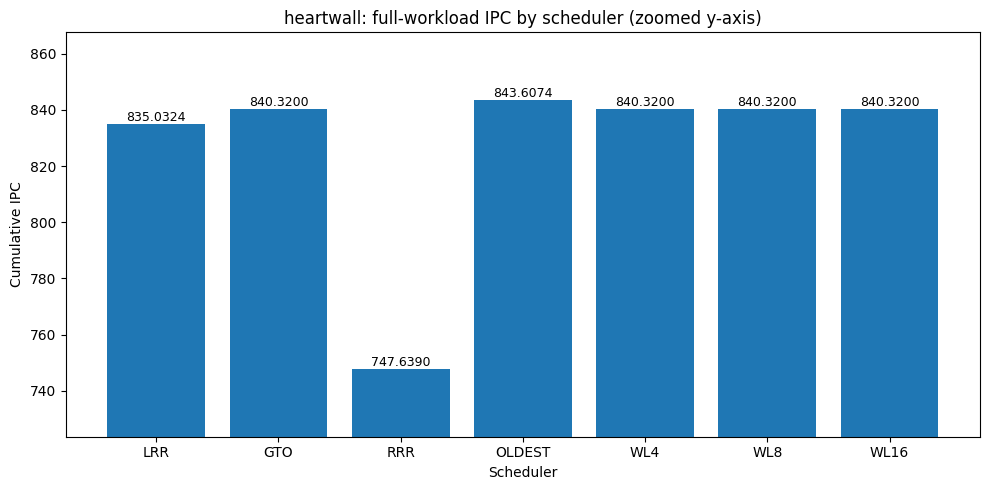

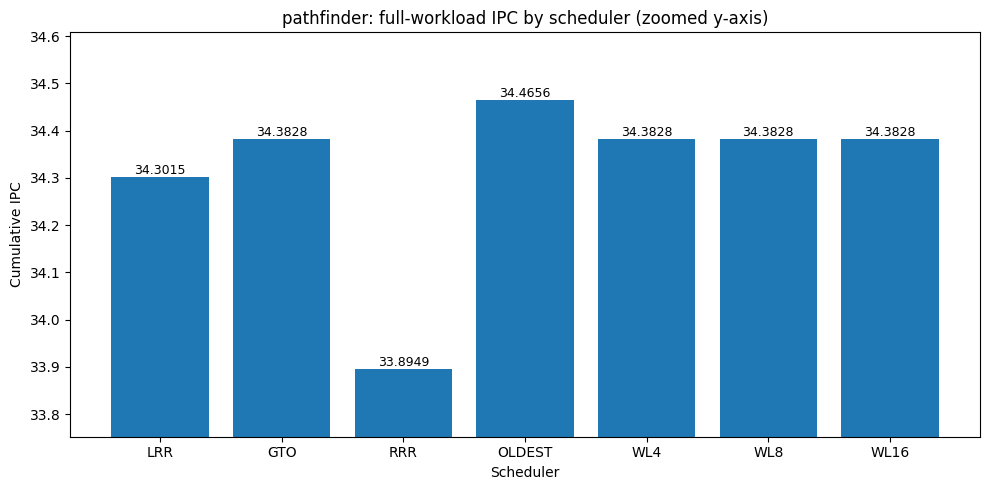

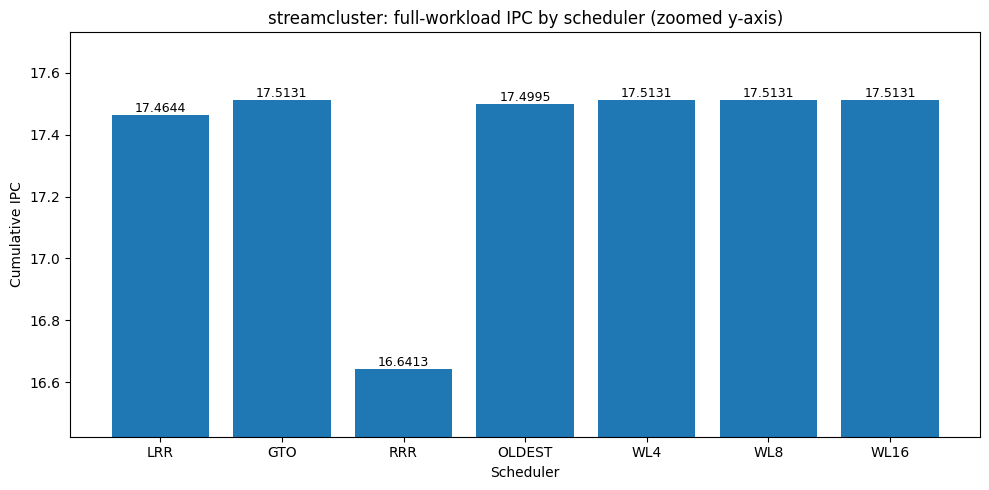

In [8]:
for workload in WORKLOADS:
    values = ipc.loc[workload, SCHEDULERS]
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar([s.upper() for s in SCHEDULERS], values.to_numpy())

    lo, hi = values.min(), values.max()
    padding = (hi - lo) * 0.25 if hi != lo else max(0.01, hi * 0.01)
    ax.set_ylim(max(0, lo - padding), hi + padding)
    ax.set_title(f"{workload}: full-workload IPC by scheduler (zoomed y-axis)")
    ax.set_xlabel("Scheduler")
    ax.set_ylabel("Cumulative IPC")

    for bar, v in zip(bars, values):
        ax.annotate(
            f"{v:.4f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center", va="bottom", fontsize=9,
        )

    fig.tight_layout()
    if SAVE_PLOTS:
        fig.savefig(PLOT_DIR / f"{workload}_ipc.png", dpi=200)
    plt.show()
